In [1]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from mpl_toolkits.mplot3d import Axes3D
import os
import matplotlib.pyplot as plt
import time

#Mes imports



os.chdir(r'C:\Users\nberr\Documents\Code\python\Modules')
import Slider_plot
importlib.reload(Slider_plot)
from Slider_plot import *
import Slider_plot_v2
importlib.reload(Slider_plot_v2)
from Slider_plot_v2 import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
from Spectra_computation_func import *
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func  import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Extinction_changes')
import nano_objects
importlib.reload(nano_objects)
from nano_objects import *


from matplotlib.widgets import Slider, Button


## Create a Nano_objecterial class for future implementation

get gold index data

Get data

In [2]:
# Get the Jhonson and Christy permittivity.
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\Data_refractive_index'
fname = 'Au - jhonson Christy.csv'
data = get_permittivity_tabulated_data(dir_root, fname)

Lda = data['lambda']*1e-9
Au_n = data['n']
Au_k = data['k']

interpolate data

In [3]:
n = sc.interpolate.interp1d(Lda, Au_n, kind='cubic', bounds_error=False, fill_value=1)
k = sc.interpolate.interp1d(Lda, Au_k, kind='cubic', bounds_error=False, fill_value=0)

Lambda = np.linspace(400e-9, 750e-9, 1000)

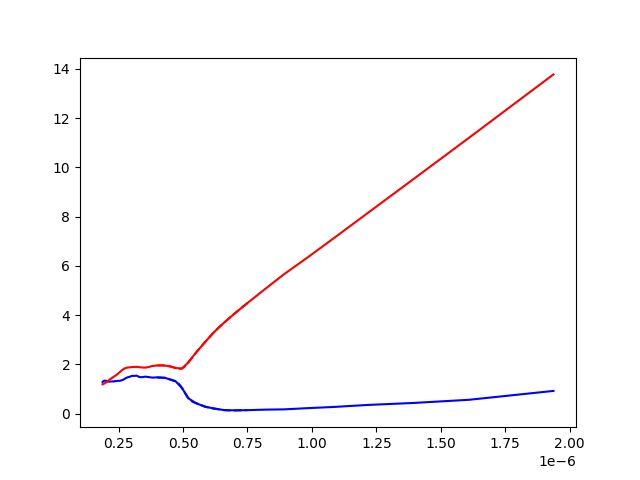

In [4]:
fig = plt.figure()

plt.plot(Lda, Au_n, color='b', label = 'n')
plt.plot(Lda, Au_k, color='r', label = 'k')

plt.plot(Lambda, n(Lambda), color='b', linestyle = '--')
plt.plot(Lambda, k(Lambda), color='r', linestyle = '--')

Create objects

In [ ]:
dir_to_save = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Ellipsoid simulations\a=51, c=10, n_ext = 1,29, gamma_corr=130meV'
save_data = 0

alpha = 1.42e-5 #in K-1 / thermal expansion coeff
dT=1


eps_ext_ini = (1.29)**2
AR = 5.0
a_ini = 51e-9
c_ini=a_ini/AR

w_p = 9.01
gamma_0 = 67e-3
gamma_corr = 130e-3


deps_1_ini = 0
deps_2_ini  = 0



# Object in equilibrium

a=a_ini
c=c_ini
eps_ext = eps_ext_ini
deps_1 = deps_1_ini
deps_2 = deps_2_ini
Gold_ellipse = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = 0, deps_2 = 0, w_p = w_p, gamma_0=gamma_0, gamma_corr=gamma_corr)
fname = 'a_{:.2f}_c_{:.2f}_eps_m_{:.3f}_deps1_{}_deps2_{}'.format(a*1e9, c*1e9, eps_ext_ini, deps_1, deps_2)

print(Gold_ellipse.L)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse)


a=a_ini
c=c_ini
eps_ext = eps_ext_ini
deps_1 = 0.001
deps_2 = deps_2_ini
Gold_ellipse_with_deps_1 = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = deps_1, deps_2 = deps_2, w_p = w_p, gamma_0=gamma_0, gamma_corr=gamma_corr)
fname = 'a_{:.2f}_c_{:.2f}_eps_m_{:.3f}_deps1_{}_deps2_{}'.format(a*1e9, c*1e9, eps_ext_ini, deps_1, deps_2)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse_with_deps_1)

a=a_ini
c=c_ini
eps_ext = eps_ext_ini
deps_1 = deps_1_ini
deps_2 = 0.001
Gold_ellipse_with_deps_2 = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = deps_1, deps_2 = deps_2, w_p = w_p, gamma_0=gamma_0, gamma_corr=gamma_corr)
fname = 'a_{:.2f}_c_{:.2f}_eps_m_{:.3f}_deps1_{}_deps2_{}'.format(a*1e9, c*1e9, eps_ext_ini, deps_1, deps_2)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse_with_deps_2)


a=a_ini + dT*alpha*a_ini
c=c_ini + dT*alpha*c_ini
eps_ext = eps_ext_ini
deps_1 = deps_1_ini
deps_2 = deps_2_ini
Gold_ellipse_with_dilatation = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = deps_1, deps_2 = deps_2, w_p = w_p, gamma_0=gamma_0, gamma_corr=gamma_corr)
fname = 'a_{:.5f}_c_{:.5f}_eps_m_{:.3f}_deps1_{}_deps2_{}_dilatation_dT_{}_K'.format(a*1e9, c*1e9, eps_ext_ini, deps_1, deps_2, dT)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse_with_dilatation)




0.12475804378826086


## élongation horizontale, contraction verticale, avec volume conservé :

Volume ellispoide : $V = \frac{4}{3} \pi abc$

Elongation horizontale : a -> a+ $\alpha \cdot dT \cdot a$

On pose c = c - $\eta \cdot c$

La conservation de volume impose $\eta = 1 - \frac{1}{1+(\alpha \cdot dT)^2}$

In [21]:
a=a_ini + dT*alpha*a_ini
c= c_ini - c_ini * (1 - 1 /(1 + (alpha*dT))**2)
eps_ext = eps_ext_ini
deps_1 = deps_1_ini
deps_2 = deps_2_ini
Gold_ellipse_with_acoustic_mode = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = deps_1, deps_2 = deps_2, w_p = w_p, gamma_0=gamma_0, gamma_corr=gamma_corr)
fname = 'a_{:.5f}_c_{:.5f}_eps_m_{:.3f}_deps1_{}_deps2_{}_contraction_dT_{}_K'.format(a*1e9, c*1e9, eps_ext_ini, deps_1, deps_2, dT)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse_with_acoustic_mode)


Compute the relative area and position changes

In [27]:
dL = (Gold_ellipse_with_acoustic_mode.L - Gold_ellipse.L)
L = Gold_ellipse.L
print(-2*dL/L)
print(dL/L**2 * 1.664 *0.5 * (1240/632)**2/(9.01**2))


V2 = Gold_ellipse_with_dilatation.a*Gold_ellipse_with_dilatation.a*Gold_ellipse_with_dilatation.c*4/3*np.pi
V1 = Gold_ellipse.a*Gold_ellipse.a*Gold_ellipse.c*4/3*np.pi

print((V2-V1)/V1)

6.73936175958183e-05
-1.0656219934864011e-05
4.2600604922856536e-05


## Try to make some parameter vary

In [7]:
slider_bool = 1

In [8]:
def plot_LSPR(arg_cte, arg_var, labels=False) :
    a = arg_var[0]
    c = arg_var[1]
    eps_ext = arg_var[2]


    mat = arg_cte[0]

    #vary matter
    mat.a = a
    mat.c = c
    mat.eps_ext = eps_ext
    mat.update()

    sigma_abs, sigma_scat, sigma_ext = mat.sigma_abs, mat.sigma_scat, mat.sigma_ext


    Labels = []
    
    if labels :
        Labels.append(Label_info(label = 'Sigma_abs', linestyle = '-', color = 'black'))
        Labels.append(Label_info(label = 'Sigma_ext', linestyle = '-', color = 'red'))

    return(mat.wl*1e9, [sigma_abs*1e15, sigma_ext*1e15], Labels)

Figure(900x400)
Axes(0.125,0.11;0.775x0.77)
['a', 'c', '$\\varepsilon_m$']


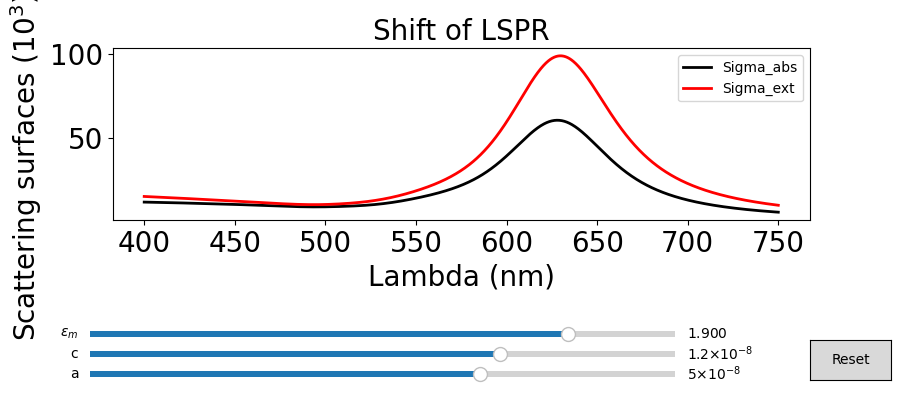

In [9]:
LSPR_plot = Param_slider()
LSPR_plot.add_param(r'a', 50e-9, 30e-9, 60e-9, label_power =9)
LSPR_plot.add_param(r'c', 12e-9, 5e-9, 15e-9, label_power =9)
LSPR_plot.add_param(r'$\varepsilon_m$', 1.9, 1, 1.45**2, label_power=0)

LSPR_plot.plot(plot_LSPR, [Gold_ellipse], titre='Shift of LSPR', xtitle='Lambda (nm)', ytitle=r'Scattering surfaces (10$^3$) nm$^2$')

In [10]:
eps_m = (1.29)**2
AR = 5.0
a = 51.e-9
c=a/AR

w_p = 9.01
gamma_0 = 67e-3
gamma_corr = 130e-3

ND2 = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_m, w_p = w_p, gamma_0 = gamma_0, gamma_corr = 0)
ND = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_m, w_p = w_p, gamma_0 = gamma_0, gamma_corr = gamma_corr)


(array([1.96890469e+00, 2.53043468e-01, 5.66245299e-14]), array([[ 1.22172351e-06,  2.27218283e-07,  5.99355607e-21],
       [ 2.27218283e-07,  1.07501346e-05, -1.15778456e-18],
       [ 5.99355607e-21, -1.15778456e-18,  2.47818912e-31]]))
[1.96890469e+00 2.53043468e-01 5.66245299e-14]


Text(0.7, 0.7, 'lda_c = 629.8 nm, \n w = 253.0 meV, \n Area = 22507.1 eV nm2')

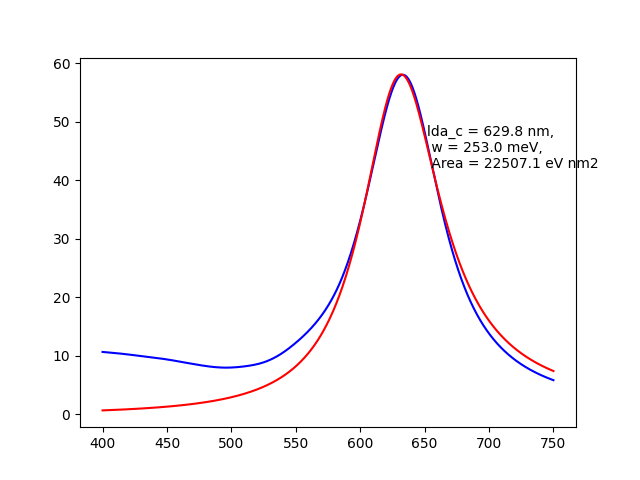

In [11]:


E_min, E_max = 1240/740*1e-9, 1240/500*1e-9

res = sc.optimize.curve_fit(Lorentz_no_offset, 1240/ND.wl*1e-9, ND.sigma_abs, p0=[2, 0.2, 100e-15] )


print(res)

print(res[0])


# fig, ax = plt.subplots()
# ax.plot(1240/ND.wl*1e-9, ND.sigma_abs*1e15, color='blue')
# ax.plot(1240/ND.wl*1e-9, Lorentz_no_offset(1240/ND.wl*1e-9, *res[0])*1e15, color='black')



fig, ax = plt.subplots()
ax.plot(ND.wl*1e9, ND.sigma_abs*1e15, color='blue')
#ax.plot(ND.wl*1e9, Lorentz_no_offset(1240/ND.wl*1e-9, *res[0])*1e15, color='black', linestyle='--')

ax.plot(ND.wl*1e9, Lorentz_no_offset(1240/ND.wl*1e-9, 1240/631.69, 0.23572, 21520*2/np.pi*1e-18/0.23572)*1e15, color='red')


ax.text(0.7, 0.7, 'lda_c = {:.1f} nm, \n w = {:.1f} meV, \n Area = {:.1f} eV nm2'.format(1240/res[0][0], res[0][1]*1e3, res[0][2]*res[0][1]*np.pi/2*1e18),transform=ax.transAxes)

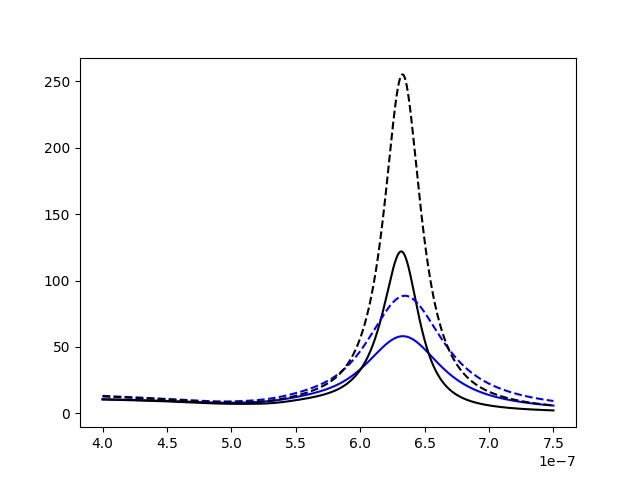

In [12]:
fig, ax = plt.subplots()

ax.plot(ND.wl, ND.sigma_abs*1e15, color='blue')
ax.plot(ND2.wl, ND2.sigma_abs*1e15, color='black')


ax.plot(ND.wl, ND.sigma_ext*1e15, color='blue', linestyle='--')
ax.plot(ND2.wl, ND2.sigma_ext*1e15, color='black', linestyle='--')